# Funded-stage payout analysis

Post-eval income modeling. Where the eval notebook maximizes **P(pass)**, this one
models the funded account as a renewal-reward process and looks at the
**distribution of dollars withdrawn** over a 1–2 month horizon, and its
**downside** (p25) and **blow-up rate** — because a breach ends all future income.

Reuses your upstream stack unchanged (`backtest_entries`, `EmpiricalStrategy`).
The funded configs live in `Funded.py`; **verify the `# VERIFY` flags** against
the live rule docs before trusting numbers.

### Setup — find the project dir (same pattern as the eval notebook)

In [1]:
import os, sys
SEARCH_ROOT = r"C:\\Users\\2115h\\Desktop\\Trading"
PROJECT_DIR = next((r for r, d, f in os.walk(SEARCH_ROOT)
                    if "Firms.py" in f and "__pycache__" not in r), os.getcwd())
os.chdir(PROJECT_DIR); sys.path.insert(0, PROJECT_DIR)
print("Project dir:", PROJECT_DIR)

Project dir: C:\\Users\\2115h\\Desktop\\Trading\Propfirm Convex Analysis\Rules


In [2]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt
from Backtest import load_ohlc, backtest_entries, ledger_for_rr, measured_winrate
from Strategy import EmpiricalStrategy
from Funded import (FUNDED, get_funded, simulate_funded, payout_geometry,
                    plot_payout_heatmap, plot_withdrawn_dist, compare_firms)
from strategies.new_jj import NewJJ

# ===================== KNOBS =====================
DATA_PATH   = "data/NQ.ohlcv-1m.parquet"
FUNDED_KEY  = "topstep_std"          # apex_eod, apex_intraday, lucid, tradeify_growth,
                                     # mffu_rapid, topstep_std, topstep_cons
BOS_TF      = "3min"; SWING_K = 2; K_STOP_ATR = 3; MAX_HOLD = 60
HORIZON     = 42                     # trading days: 21 ~ one month, 42 ~ two months
RR_GRID     = [1.0, 1.5, 2.0, 3.0]
RISK_PCTS   = np.round(np.arange(0.25, 2.51, 0.25), 2)
ALL_FUNDED  = list(FUNDED)
# =================================================
fc = get_funded(FUNDED_KEY)
print("Modeling:", fc.name)

Modeling: Topstep XFA (Standard)


## 1. Funded configs
Read these back against the rule `.md` files. The fields that move income most:
`withdraw_buffer`, `min_daily_profit`, `winning_days_required`, `consistency_pct`,
`profit_split`, `reset_floor_on_payout`.

In [3]:
for k, f in FUNDED.items():
    print(f"{k:15s} {f.name:26s} start=${f.start_balance:>6,.0f} buf=${f.withdraw_buffer:>7,.0f} "
          f"win${f.min_daily_profit:>4.0f}x{f.winning_days_required} "
          f"cons={str(f.consistency_pct):5s} split={f.profit_split:.0%} "
          f"reset={str(f.reset_floor_on_payout):5s} cap={str(f.payout_cap)}")

apex_eod        Apex PA (EOD)              start=$50,000 buf=$ 52,100 win$ 250x5 cons=0.5   split=100% reset=False cap=3000
apex_intraday   Apex PA (Intraday)         start=$50,000 buf=$ 52,100 win$ 200x5 cons=0.5   split=100% reset=False cap=3000
lucid           Lucid (funded)             start=$50,000 buf=$ 52,100 win$   0x1 cons=0.4   split=90% reset=False cap=2500
tradeify_growth Tradeify Growth (funded)   start=$50,000 buf=$ 53,000 win$ 150x5 cons=0.35  split=90% reset=False cap=3000
mffu_rapid      MFFU Rapid (funded)        start=$     0 buf=$  2,100 win$   0x1 cons=None  split=90% reset=True  cap=None
topstep_std     Topstep XFA (Standard)     start=$     0 buf=$      0 win$ 150x5 cons=None  split=90% reset=True  cap=5000
topstep_cons    Topstep XFA (Consistency)  start=$     0 buf=$      0 win$   0x3 cons=0.4   split=90% reset=True  cap=6000


## 2. Build the R-ledger from your strategy
Identical to the eval flow — one entry ledger, scorable at any R:R.

In [4]:
bars = load_ohlc(DATA_PATH, rth_only=False, timeframe=None, tz="America/New_York")
E = backtest_entries(NewJJ(bos_tf=BOS_TF, swing_k=SWING_K), bars,
                     k_stop_atr=K_STOP_ATR, max_hold=MAX_HOLD)
print(E.summary())
for rr in RR_GRID:
    print(f"  {rr:>4}R  WR={measured_winrate(E, rr):5.1%}")

2337 entries over 1311 days (~1.78 trades/day) | new_jj on ?
   1.0R  WR=51.4%
   1.5R  WR=34.5%
   2.0R  WR=24.7%
   3.0R  WR=13.1%


## 3. Single funded run — the withdrawal distribution
Pick one R:R and one risk level; see the full spread of outcomes over the horizon.
`greedy_payout=True` withdraws the instant the gate opens (income-max, and usually
risk-min on $0-start firms since each payout re-anchors the floor).

Topstep XFA (Standard) @ $500/trade | E[$]=1,555  med=$414  p25=$0  blow-up=93.1%  ≥1 payout=54.6%  avg payouts=1.16


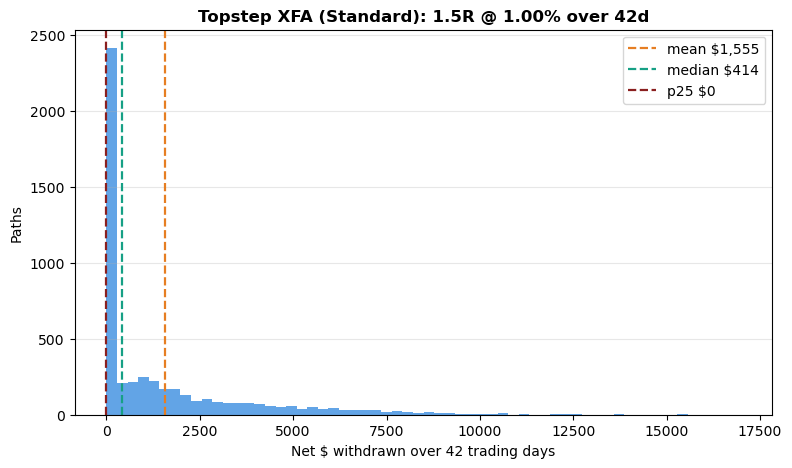

In [5]:
RR   = 1.5      # start from your eval-optimal R:R, or scan below
RISK = 1.0      # % of (nominal 50K) account per trade

R, days = ledger_for_rr(E, RR)
strat = EmpiricalStrategy(R, name=f"new_jj {RR:g}R", day_ids=days)
ref = fc.start_balance if fc.start_balance > 0 else 50_000

res = simulate_funded(strat, fc, risk_per_trade=ref*RISK/100, horizon_days=HORIZON,
                      n_paths=5000, max_trades=1200)
print(res.describe())
plot_withdrawn_dist(res, title=f"{fc.name}: {RR:g}R @ {RISK:.2f}% over {HORIZON}d"); plt.show()

## 4. Payout geometry — risk × R:R, scored on the DOWNSIDE
Left panel = p25 of net $ withdrawn (what you clear in a bad-but-survivable run).
Right panel = blow-up rate. **Read the right panel first**: reject any cell whose
ruin rate you can't stomach, *then* pick the highest-payout survivor. This is the
funded analogue of your "optimize the floor, not the mean" rule.

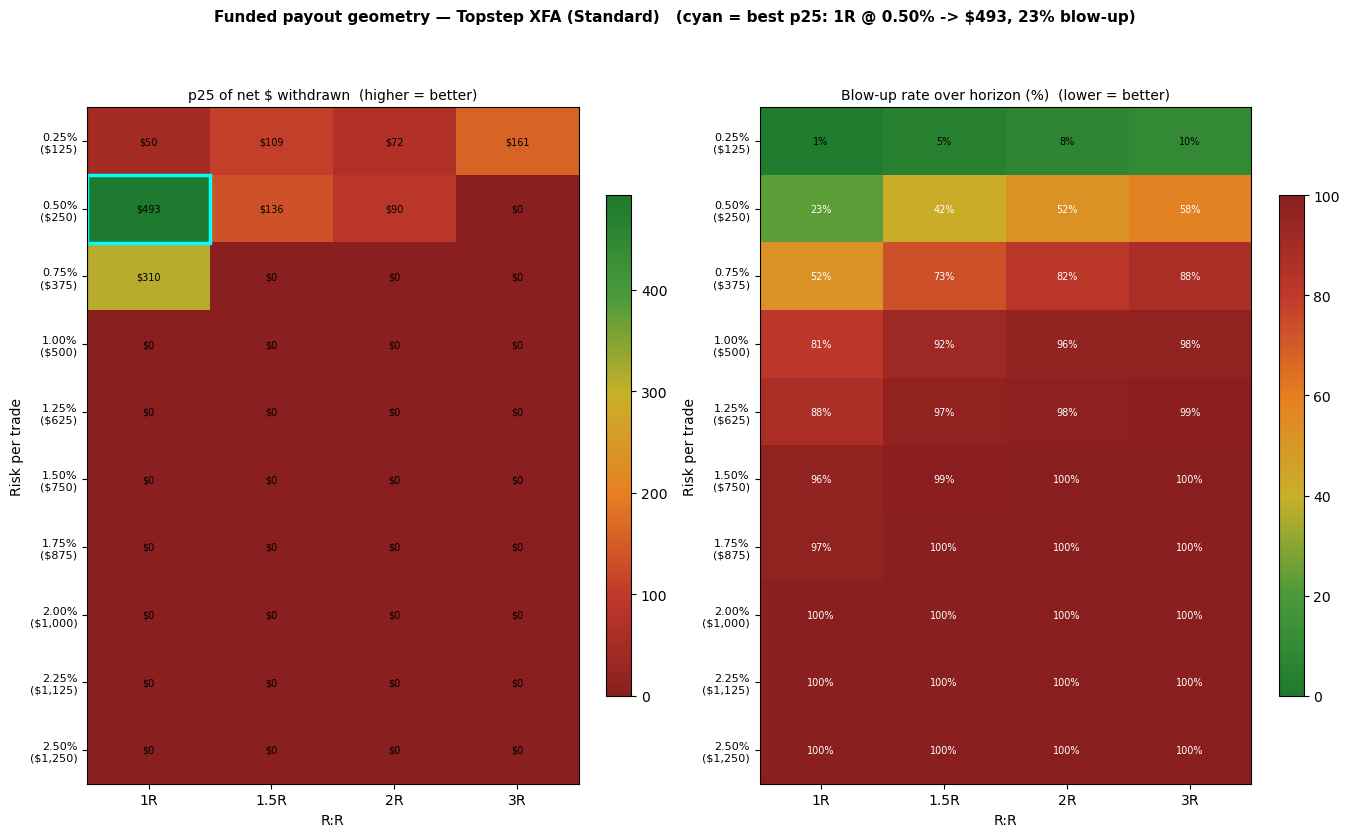

Best p25 cell: 1R @ 0.50% -> p25 $493, mean $1,455, blow-up 23%


In [6]:
grid = payout_geometry(fc, E, risk_pcts=RISK_PCTS, rr_grid=RR_GRID,
                       horizon_days=HORIZON, n_paths=3000, objective="p25")
plot_payout_heatmap(grid, fc); plt.show()
print(f"Best p25 cell: {grid['opt_rr']:g}R @ {grid['opt_risk_pct']:.2f}% "
      f"-> p25 ${grid['opt_score']:,.0f}, mean ${grid['opt_mean']:,.0f}, "
      f"blow-up {grid['opt_blowup_pct']:.0f}%")

## 5. Greedy vs let-it-ride
Does holding for a bigger single payout beat withdrawing early? Compare net income
and blow-up at the same geometry.

In [7]:
for greedy in (True, False):
    r = simulate_funded(strat, fc, ref*grid["opt_risk_pct"]/100, horizon_days=HORIZON,
                        n_paths=5000, max_trades=1200, greedy_payout=greedy)
    tag = "greedy (withdraw when eligible)" if greedy else "hold, one payout at end"
    print(f"{tag:34s} mean ${r.mean_withdrawn:>7,.0f}  p25 ${r.p25_withdrawn:>7,.0f}  "
          f"blow-up {r.blowup_rate:5.1%}")

greedy (withdraw when eligible)    mean $  1,225  p25 $    122  blow-up 42.6%
hold, one payout at end            mean $    796  p25 $      0  blow-up 45.2%


## 6. Cross-firm — income vs blow-up
Same strategy and geometry across all funded configs. The $0-start firms
(MFFU/Topstep) pay faster but sit closer to their floor; the $50K-start firms
carry more cushion. Pick the risk/RR from section 4 (or a shared baseline).

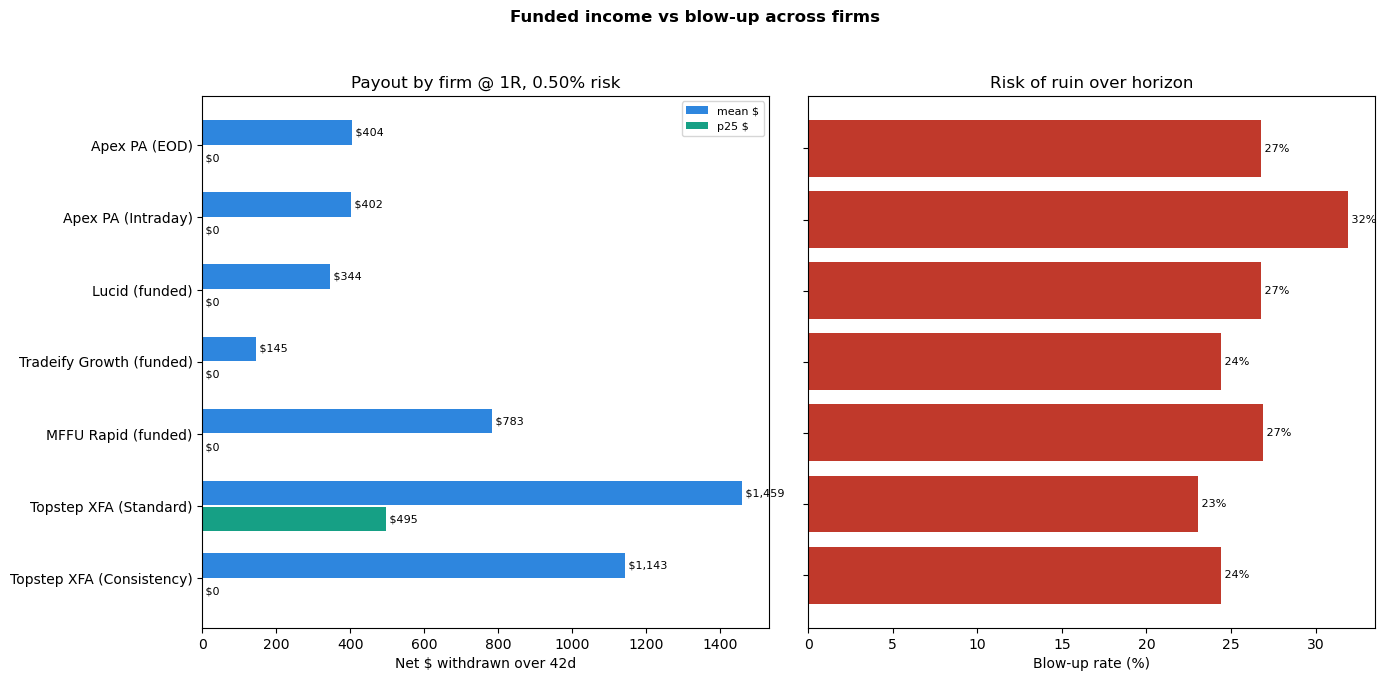

Topstep XFA (Standard)     mean $  1,459  p25 $    495  blow-up   23%
Apex PA (EOD)              mean $    404  p25 $      0  blow-up   27%
Apex PA (Intraday)         mean $    402  p25 $      0  blow-up   32%
Lucid (funded)             mean $    344  p25 $      0  blow-up   27%
Tradeify Growth (funded)   mean $    145  p25 $      0  blow-up   24%
MFFU Rapid (funded)        mean $    783  p25 $      0  blow-up   27%
Topstep XFA (Consistency)  mean $  1,143  p25 $      0  blow-up   24%


In [8]:
fig, rows = compare_firms(E, ALL_FUNDED, rr=grid["opt_rr"],
                          risk_pct=grid["opt_risk_pct"], horizon_days=HORIZON,
                          n_paths=4000); plt.show()
for name, mean, p25, blow in sorted(rows, key=lambda r: -r[2]):
    print(f"{name:26s} mean ${mean:>7,.0f}  p25 ${p25:>7,.0f}  blow-up {blow:4.0f}%")

## 7. Horizon — one month vs two
How income and ruin scale with time in the seat. Blow-up is cumulative, so a
geometry that looks fine at 21 days can degrade badly by 42.

In [9]:
for H in (21, 42):
    r = simulate_funded(strat, fc, ref*grid["opt_risk_pct"]/100, horizon_days=H,
                        n_paths=5000, max_trades=1400)
    print(f"{H:>3}d  mean ${r.mean_withdrawn:>7,.0f}  p25 ${r.p25_withdrawn:>7,.0f}  "
          f"blow-up {r.blowup_rate:5.1%}  avg payouts {r.n_payouts.mean():.2f}")

 21d  mean $    526  p25 $      0  blow-up 19.4%  avg payouts 0.86
 42d  mean $  1,197  p25 $    123  blow-up 43.9%  avg payouts 1.73
